In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

In [48]:
def set_plot_settings():

    # Основные настройки
    plt.rcParams['figure.figsize'] = (8, 6)  # Размер figure
    plt.rcParams['figure.dpi'] = 100         # Разрешение figure
    plt.rcParams['savefig.dpi'] = 300        # Разрешение при сохранении
    
    # Шрифты и текст
    plt.rcParams['font.family'] = 'serif'    # Шрифт с засечками
    plt.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif', 'CMU Serif']
    plt.rcParams['font.size'] = 14           # Размер шрифта
    plt.rcParams['mathtext.fontset'] = 'stix' # Шрифт для формул
    
    # Оси
    plt.rcParams['axes.titlesize'] = 16      # Размер заголовка
    plt.rcParams['axes.labelsize'] = 14      # Размер подписей осей
    plt.rcParams['axes.linewidth'] = 1.2     # Толщина линий осей
    
    # Деления на осях
    plt.rcParams['xtick.direction'] = 'in'   # Деления внутрь
    plt.rcParams['ytick.direction'] = 'in'   # Деления внутрь
    plt.rcParams['xtick.labelsize'] = 12     # Размер подписей делений X
    plt.rcParams['ytick.labelsize'] = 12     # Размер подписей делений Y
    plt.rcParams['xtick.major.size'] = 6     # Длина major делений X
    plt.rcParams['ytick.major.size'] = 6     # Длина major делений Y
    plt.rcParams['xtick.minor.size'] = 3     # Длина minor делений X
    plt.rcParams['ytick.minor.size'] = 3     # Длина minor делений Y
    plt.rcParams['xtick.major.width'] = 1.2  # Толщина major делений X
    plt.rcParams['ytick.major.width'] = 1.2  # Толщина major делений Y
    plt.rcParams['xtick.minor.width'] = 0.8  # Толщина minor делений X
    plt.rcParams['ytick.minor.width'] = 0.8  # Толщина minor делений Y
    
    # Легенда
    plt.rcParams['legend.fontsize'] = 12     # Размер шрифта легенды
    plt.rcParams['legend.frameon'] = True    # Рамка вокруг легенды
    plt.rcParams['legend.framealpha'] = 0.8  # Прозрачность фона легенды
    plt.rcParams['legend.fancybox'] = True   # Скругленные углы
    
    # Линии
    plt.rcParams['lines.linewidth'] = 1   # Толщина линий
    plt.rcParams['lines.markersize'] = 4    # Размер маркеров
    
    # Сетка
    plt.rcParams['grid.linewidth'] = 0.5     # Толщина линий сетки
    plt.rcParams['grid.alpha'] = 0.5         # Прозрачность сетки
    
    # Сохранение
    plt.rcParams['savefig.bbox'] = 'tight'   # Обрезка пустых полей
    plt.rcParams['savefig.pad_inches'] = 0.1 # Отступ при сохранении

set_plot_settings()

In [49]:

dataarc_arc = pd.read_csv('data_r(h)_arc_arc500.csv')
datalirs_lirs = pd.read_csv('data_r(h)_lirs_lirs500.csv')
datalfu_lfu = pd.read_csv('data_r(h)_lfu_lfu500.csv')
data2q_2q = pd.read_csv('data_r(h)_2q_2q500.csv')

data2q_arc = pd.read_csv('data_r(h)_2q_arc500.csv')
dataarc_2q = pd.read_csv('data_r(h)_arc_2q500.csv')
data2q_lirs = pd.read_csv('data_r(h)_2q_lirs500.csv')
datalirs_2q = pd.read_csv('data_r(h)_lirs_2q500.csv')
data2q_lfu = pd.read_csv('data_r(h)_2q_lfu500.csv')
datalfu_2q = pd.read_csv('data_r(h)_lfu_2q500.csv')

datalfu_lirs = pd.read_csv('data_r(h)_lfu_lirs500.csv')
datalirs_lfu = pd.read_csv('data_r(h)_lirs_lfu500.csv')
datalirs_arc = pd.read_csv('data_r(h)_lirs_arc500.csv')
dataarc_lirs = pd.read_csv('data_r(h)_arc_lirs500.csv')
datalfu_lirs = pd.read_csv('data_r(h)_lfu_lirs500.csv')
datalirs_lfu = pd.read_csv('data_r(h)_lirs_lfu500.csv')
dataarc_lfu = pd.read_csv('data_r(h)_arc_lfu500.csv')
datalfu_arc = pd.read_csv('data_r(h)_lfu_arc500.csv')

data2q = pd.read_csv('data_r(h)_2q500.csv')
datalfu = pd.read_csv('data_r(h)_lfu500.csv')
datalirs = pd.read_csv('data_r(h)_lirs500.csv')
dataarc = pd.read_csv('data_r(h)_arc500.csv')
dataperf = pd.read_csv('data_r(h)_perfect500.csv')

data2q5000 = pd.read_csv('data_r(h)_2q5000.csv')
datalfu5000 = pd.read_csv('data_r(h)_lfu5000.csv')
datalirs5000 = pd.read_csv('data_r(h)_lirs5000.csv')
dataarc5000 = pd.read_csv('data_r(h)_arc5000.csv')
dataperf5000 = pd.read_csv('data_r(h)_perfect5000.csv')


# data40 = pd.read_csv('down.csv')

In [50]:
def least_squares(x, y):
    coeff = (np.mean(x*y) - np.mean(x)*np.mean(y)) / (np.mean(x*x) - np.mean(x)*np.mean(x))
    b = np.mean(y) - coeff*np.mean(x)
    sigma_k = (((np.mean(y*y) - np.mean(y)*np.mean(y))/(np.mean(x*x)-np.mean(x)*np.mean(x)) - coeff*coeff)/12)**0.5
   
    sigma_b = sigma_k*(np.mean(x*x) - np.mean(x)*np.mean(x))**0.5
    err = sigma_b
    return coeff, err, b

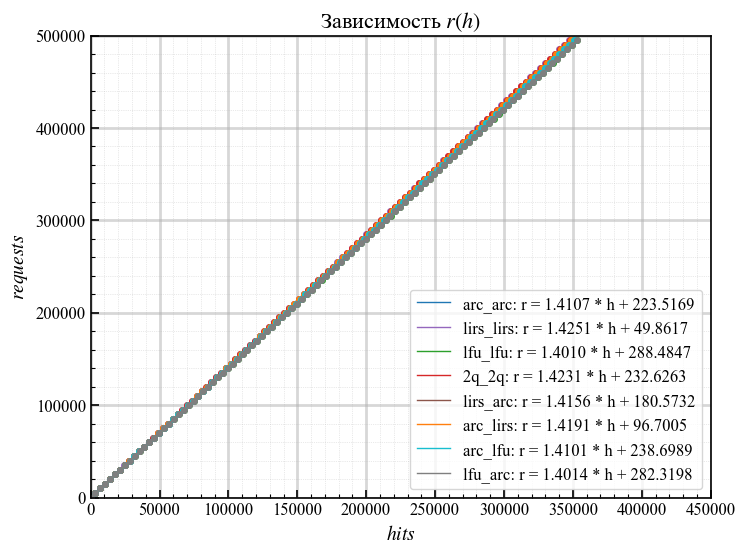

In [51]:

plt.figure()
plt.plot(dataarc_arc['h'], dataarc_arc['r'], 'o', color='tab:blue')

coeff, err, b = least_squares(dataarc_arc['h'], dataarc_arc['r'])
plt.plot(dataarc_arc['h'], coeff * dataarc_arc['h'] + b , color='tab:blue', label=f"arc_arc: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalirs_lirs['h'], datalirs_lirs['r'], 'o', color='tab:purple')

coeff, err, b = least_squares(datalirs_lirs['h'], datalirs_lirs['r'])
plt.plot(datalirs_lirs['h'], coeff * datalirs_lirs['h'] + b , color='tab:purple', label=f"lirs_lirs: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalfu_lfu['h'], datalfu_lfu['r'], 'o', color='tab:green')

coeff, err, b = least_squares(datalfu_lfu['h'], datalfu_lfu['r'])
plt.plot(datalfu_lfu['h'], coeff * datalfu_lfu['h'] + b , color='tab:green', label=f"lfu_lfu: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(data2q_2q['h'], data2q_2q['r'], 'o', color='tab:red')

coeff, err, b = least_squares(data2q_2q['h'], data2q_2q['r'])
plt.plot(data2q_2q['h'], coeff * data2q_2q['h'] + b , color='tab:red', label=f"2q_2q: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalirs_arc['h'], datalirs_arc['r'], 'o', color='tab:brown')

coeff, err, b = least_squares(datalirs_arc['h'], datalirs_arc['r'])
plt.plot(datalirs_arc['h'], coeff * datalirs_arc['h'] + b , color='tab:brown', label=f"lirs_arc: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(dataarc_lirs['h'], dataarc_lirs['r'], 'o', color='tab:orange')

coeff, err, b = least_squares(dataarc_lirs['h'], dataarc_lirs['r'])
plt.plot(dataarc_lirs['h'], coeff * dataarc_lirs['h'] + b , color='tab:orange', label=f"arc_lirs: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(dataarc_lfu['h'], dataarc_lfu['r'], 'o', color='tab:cyan')

coeff, err, b = least_squares(dataarc_lfu['h'], dataarc_lfu['r'])
plt.plot(dataarc_lfu['h'], coeff * dataarc_lfu['h'] + b , color='tab:cyan', label=f"arc_lfu: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalfu_arc['h'], datalfu_arc['r'], 'o', color='tab:grey')

coeff, err, b = least_squares(datalfu_arc['h'], datalfu_arc['r'])
plt.plot(datalfu_arc['h'], coeff * datalfu_arc['h'] + b , color='tab:grey', label=f"lfu_arc: r = {coeff:.4f} * h + {b:.4f}")




plt.legend()


plt.xlim(0, 450000)
plt.ylim(0, 500000)
plt.minorticks_on()
plt.grid(which='major', lw = 2)
plt.grid(which='minor', color = '#aaa', ls=':')
plt.title("Зависимость $r(h)$")
plt.xlabel("$hits$")
plt.ylabel("$requests$")
plt.savefig('plot_500_1lvl_1.png', dpi=500)
plt.show()
plt.close()



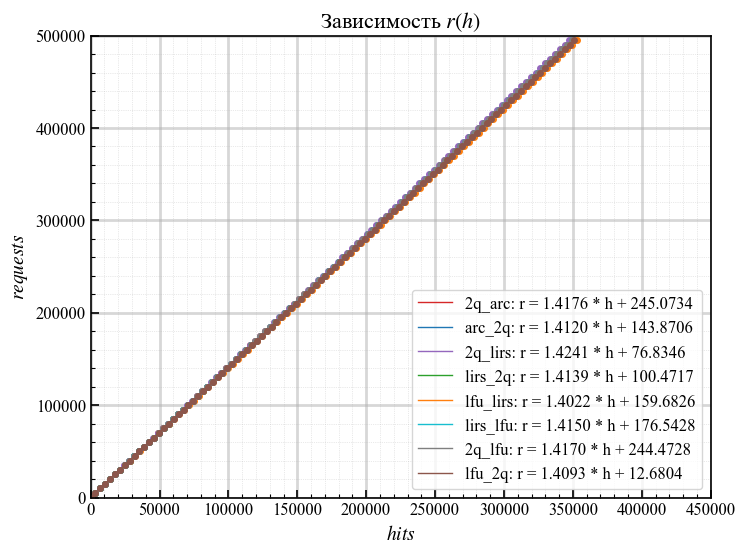

In [52]:

plt.figure()
plt.plot(data2q_arc['h'], data2q_arc['r'], 'o', color='tab:red')

coeff, err, b = least_squares(data2q_arc['h'], data2q_arc['r'])
plt.plot(data2q_arc['h'], coeff * data2q_arc['h'] + b , color='tab:red', label=f"2q_arc: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(dataarc_2q['h'], dataarc_2q['r'], 'o', color='tab:blue')

coeff, err, b = least_squares(dataarc_2q['h'], dataarc_2q['r'])
plt.plot(dataarc_2q['h'], coeff * dataarc_2q['h'] + b , color='tab:blue', label=f"arc_2q: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(data2q_lirs['h'], data2q_lirs['r'], 'o', color='tab:purple')

coeff, err, b = least_squares(data2q_lirs['h'], data2q_lirs['r'])
plt.plot(data2q_lirs['h'], coeff * data2q_lirs['h'] + b , color='tab:purple', label=f"2q_lirs: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalirs_2q['h'], datalirs_2q['r'], 'o', color='tab:green')

coeff, err, b = least_squares(datalirs_2q['h'], datalirs_2q['r'])
plt.plot(datalirs_2q['h'], coeff * datalirs_2q['h'] + b , color='tab:green', label=f"lirs_2q: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalfu_lirs['h'], datalfu_lirs['r'], 'o', color='tab:orange')

coeff, err, b = least_squares(datalfu_lirs['h'], datalfu_lirs['r'])
plt.plot(datalfu_lirs['h'], coeff * datalfu_lirs['h'] + b , color='tab:orange', label=f"lfu_lirs: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalirs_lfu['h'], datalirs_lfu['r'], 'o', color='tab:cyan')

coeff, err, b = least_squares(datalirs_lfu['h'], datalirs_lfu['r'])
plt.plot(datalirs_lfu['h'], coeff * datalirs_lfu['h'] + b , color='tab:cyan', label=f"lirs_lfu: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(data2q_lfu['h'], data2q_lfu['r'], 'o', color='tab:grey')

coeff, err, b = least_squares(data2q_lfu['h'], data2q_lfu['r'])
plt.plot(data2q_lfu['h'], coeff * data2q_lfu['h'] + b , color='tab:grey', label=f"2q_lfu: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalfu_2q['h'], datalfu_2q['r'], 'o', color='tab:brown')

coeff, err, b = least_squares(datalfu_2q['h'], datalfu_2q['r'])
plt.plot(datalfu_2q['h'], coeff * datalfu_2q['h'] + b , color='tab:brown', label=f"lfu_2q: r = {coeff:.4f} * h + {b:.4f}")


plt.legend()


plt.xlim(0, 450000)
plt.ylim(0, 500000)
plt.minorticks_on()
plt.grid(which='major', lw = 2)
plt.grid(which='minor', color = '#aaa', ls=':')
plt.title("Зависимость $r(h)$")
plt.xlabel("$hits$")
plt.ylabel("$requests$")
plt.savefig('plot_500_2lvl_2.png', dpi=500)
plt.show()
plt.close()



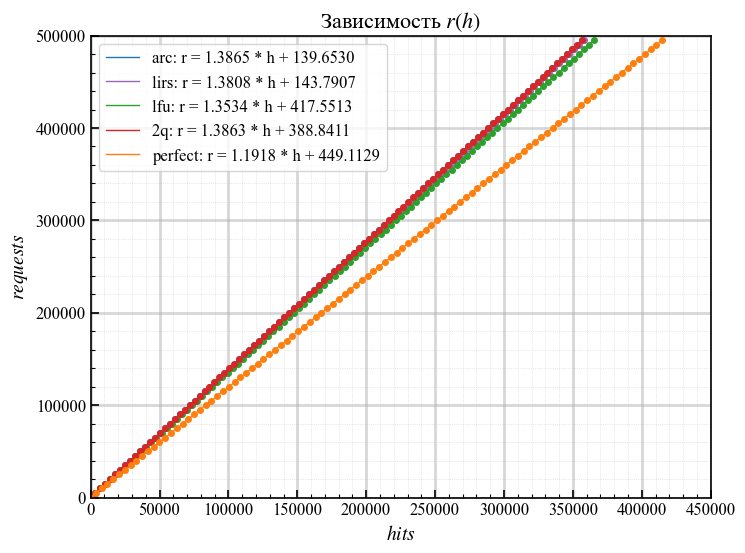

In [53]:

plt.figure()
plt.plot(dataarc['h'], dataarc['r'], 'o', color='tab:blue')

coeff, err, b = least_squares(dataarc['h'], dataarc['r'])
plt.plot(dataarc['h'], coeff * dataarc['h'] + b , color='tab:blue', label=f"arc: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalirs['h'], datalirs['r'], 'o', color='tab:purple')

coeff, err, b = least_squares(datalirs['h'], datalirs['r'])
plt.plot(datalirs['h'], coeff * datalirs['h'] + b , color='tab:purple', label=f"lirs: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalfu['h'], datalfu['r'], 'o', color='tab:green')

coeff, err, b = least_squares(datalfu['h'], datalfu['r'])
plt.plot(datalfu['h'], coeff * datalfu['h'] + b , color='tab:green', label=f"lfu: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(data2q['h'], data2q['r'], 'o', color='tab:red')

coeff, err, b = least_squares(data2q['h'], data2q['r'])
plt.plot(data2q['h'], coeff * data2q['h'] + b , color='tab:red', label=f"2q: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(dataperf['h'], dataperf['r'], 'o', color='tab:orange')

coeff, err, b = least_squares(dataperf['h'], dataperf['r'])
plt.plot(dataperf['h'], coeff * dataperf['h'] + b , color='tab:orange', label=f"perfect: r = {coeff:.4f} * h + {b:.4f}")


plt.legend()


plt.xlim(0, 450000)
plt.ylim(0, 500000)
plt.minorticks_on()
plt.grid(which='major', lw = 2)
plt.grid(which='minor', color = '#aaa', ls=':')
plt.title("Зависимость $r(h)$")
plt.xlabel("$hits$")
plt.ylabel("$requests$")
plt.savefig('plot_500_1lvl.png', dpi=500)
plt.show()
plt.close()


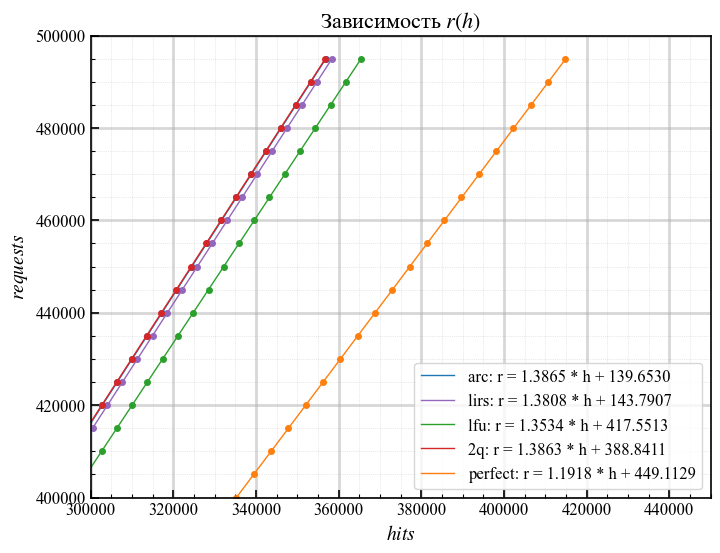

In [54]:

plt.figure()
plt.plot(dataarc['h'], dataarc['r'], 'o', color='tab:blue')

coeff, err, b = least_squares(dataarc['h'], dataarc['r'])
plt.plot(dataarc['h'], coeff * dataarc['h'] + b , color='tab:blue', label=f"arc: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalirs['h'], datalirs['r'], 'o', color='tab:purple')

coeff, err, b = least_squares(datalirs['h'], datalirs['r'])
plt.plot(datalirs['h'], coeff * datalirs['h'] + b , color='tab:purple', label=f"lirs: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalfu['h'], datalfu['r'], 'o', color='tab:green')

coeff, err, b = least_squares(datalfu['h'], datalfu['r'])
plt.plot(datalfu['h'], coeff * datalfu['h'] + b , color='tab:green', label=f"lfu: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(data2q['h'], data2q['r'], 'o', color='tab:red')

coeff, err, b = least_squares(data2q['h'], data2q['r'])
plt.plot(data2q['h'], coeff * data2q['h'] + b , color='tab:red', label=f"2q: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(dataperf['h'], dataperf['r'], 'o', color='tab:orange')

coeff, err, b = least_squares(dataperf['h'], dataperf['r'])
plt.plot(dataperf['h'], coeff * dataperf['h'] + b , color='tab:orange', label=f"perfect: r = {coeff:.4f} * h + {b:.4f}")


plt.legend()


plt.xlim(300000, 450000)
plt.ylim(400000, 500000)
plt.minorticks_on()
plt.grid(which='major', lw = 2)
plt.grid(which='minor', color = '#aaa', ls=':')
plt.title("Зависимость $r(h)$")
plt.xlabel("$hits$")
plt.ylabel("$requests$")
plt.savefig('plot_500_1lvl_end.png', dpi=500)
plt.show()
plt.close()


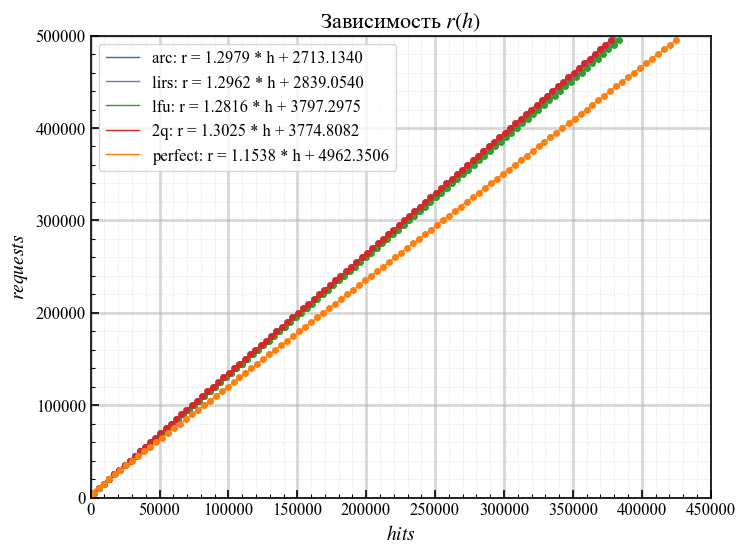

In [55]:
plt.figure()
plt.plot(dataarc5000['h'], dataarc5000['r'], 'o', color='tab:blue')

coeff, err, b = least_squares(dataarc5000['h'], dataarc5000['r'])
plt.plot(dataarc5000['h'], coeff * dataarc5000['h'] + b , color='tab:blue', label=f"arc: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalirs5000['h'], datalirs5000['r'], 'o', color='tab:purple')

coeff, err, b = least_squares(datalirs5000['h'], datalirs5000['r'])
plt.plot(datalirs5000['h'], coeff * datalirs5000['h'] + b , color='tab:purple', label=f"lirs: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalfu5000['h'], datalfu5000['r'], 'o', color='tab:green')

coeff, err, b = least_squares(datalfu5000['h'], datalfu5000['r'])
plt.plot(datalfu5000['h'], coeff * datalfu5000['h'] + b , color='tab:green', label=f"lfu: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(data2q5000['h'], data2q5000['r'], 'o', color='tab:red')

coeff, err, b = least_squares(data2q5000['h'], data2q['r'])
plt.plot(data2q5000['h'], coeff * data2q5000['h'] + b , color='tab:red', label=f"2q: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(dataperf5000['h'], dataperf5000['r'], 'o', color='tab:orange')

coeff, err, b = least_squares(dataperf5000['h'], dataperf5000['r'])
plt.plot(dataperf5000['h'], coeff * dataperf5000['h'] + b , color='tab:orange', label=f"perfect: r = {coeff:.4f} * h + {b:.4f}")

plt.legend()


plt.xlim(0, 450000)
plt.ylim(0, 500000)
plt.minorticks_on()
plt.grid(which='major', lw = 2)
plt.grid(which='minor', color = '#aaa', ls=':')
plt.title("Зависимость $r(h)$")
plt.xlabel("$hits$")
plt.ylabel("$requests$")
plt.savefig('plot_5000_1lvl.png', dpi=500)
plt.show()
plt.close()


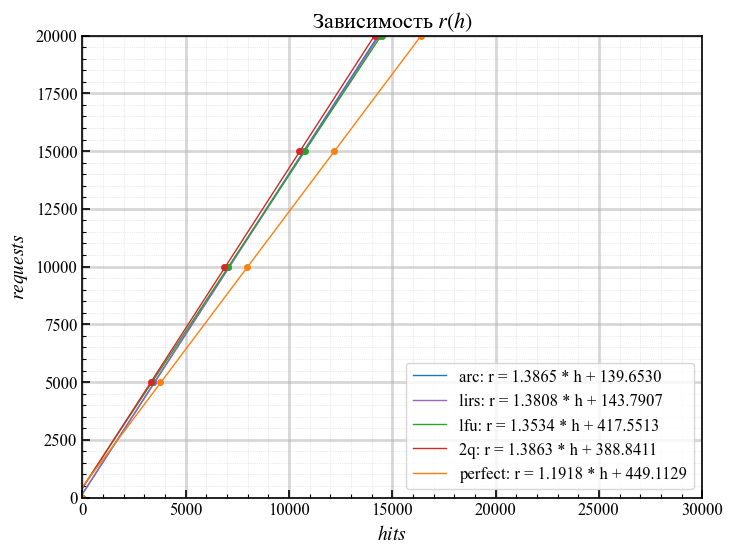

In [56]:

plt.figure()
plt.plot(dataarc['h'], dataarc['r'], 'o', color='tab:blue')

coeff, err, b = least_squares(dataarc['h'], dataarc['r'])
plt.plot(dataarc['h'], coeff * dataarc['h'] + b , color='tab:blue', label=f"arc: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalirs['h'], datalirs['r'], 'o', color='tab:purple')

coeff, err, b = least_squares(datalirs['h'], datalirs['r'])
plt.plot(datalirs['h'], coeff * datalirs['h'] + b , color='tab:purple', label=f"lirs: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalfu['h'], datalfu['r'], 'o', color='tab:green')

coeff, err, b = least_squares(datalfu['h'], datalfu['r'])
plt.plot(datalfu['h'], coeff * datalfu['h'] + b , color='tab:green', label=f"lfu: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(data2q['h'], data2q['r'], 'o', color='tab:red')

coeff, err, b = least_squares(data2q['h'], data2q['r'])
plt.plot(data2q['h'], coeff * data2q['h'] + b , color='tab:red', label=f"2q: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(dataperf['h'], dataperf['r'], 'o', color='tab:orange')

coeff, err, b = least_squares(dataperf['h'], dataperf['r'])
plt.plot(dataperf['h'], coeff * dataperf['h'] + b , color='tab:orange', label=f"perfect: r = {coeff:.4f} * h + {b:.4f}")


plt.legend()


plt.xlim(0, 30000)
plt.ylim(0, 20000)
plt.minorticks_on()
plt.grid(which='major', lw = 2)
plt.grid(which='minor', color = '#aaa', ls=':')
plt.title("Зависимость $r(h)$")
plt.xlabel("$hits$")
plt.ylabel("$requests$")
plt.savefig('plot_500_1lvl_start.png', dpi=500)
plt.show()
plt.close()


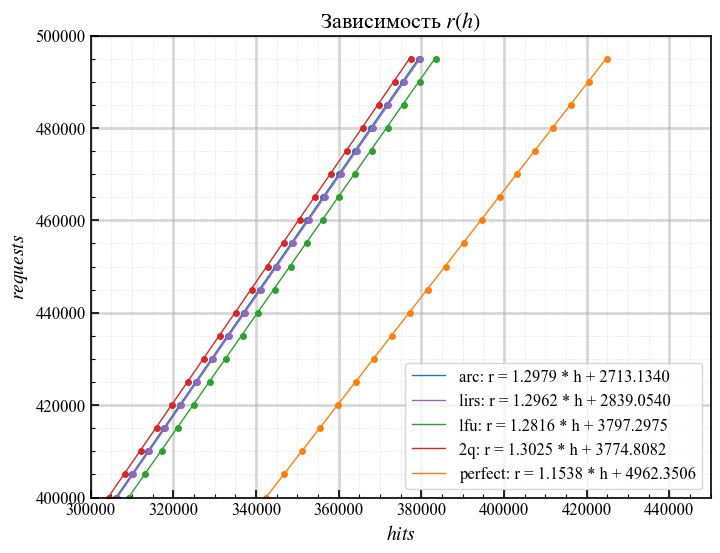

In [57]:
plt.figure()
plt.plot(dataarc5000['h'], dataarc5000['r'], 'o', color='tab:blue')

coeff, err, b = least_squares(dataarc5000['h'], dataarc5000['r'])
plt.plot(dataarc5000['h'], coeff * dataarc5000['h'] + b , color='tab:blue', label=f"arc: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalirs5000['h'], datalirs5000['r'], 'o', color='tab:purple')

coeff, err, b = least_squares(datalirs5000['h'], datalirs5000['r'])
plt.plot(datalirs5000['h'], coeff * datalirs5000['h'] + b , color='tab:purple', label=f"lirs: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalfu5000['h'], datalfu5000['r'], 'o', color='tab:green')

coeff, err, b = least_squares(datalfu5000['h'], datalfu5000['r'])
plt.plot(datalfu5000['h'], coeff * datalfu5000['h'] + b , color='tab:green', label=f"lfu: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(data2q5000['h'], data2q5000['r'], 'o', color='tab:red')

coeff, err, b = least_squares(data2q5000['h'], data2q['r'])
plt.plot(data2q5000['h'], coeff * data2q5000['h'] + b , color='tab:red', label=f"2q: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(dataperf5000['h'], dataperf5000['r'], 'o', color='tab:orange')

coeff, err, b = least_squares(dataperf5000['h'], dataperf5000['r'])
plt.plot(dataperf5000['h'], coeff * dataperf5000['h'] + b , color='tab:orange', label=f"perfect: r = {coeff:.4f} * h + {b:.4f}")

plt.legend()


plt.xlim(300000, 450000)
plt.ylim(400000, 500000)
plt.minorticks_on()
plt.grid(which='major', lw = 2)
plt.grid(which='minor', color = '#aaa', ls=':')
plt.title("Зависимость $r(h)$")
plt.xlabel("$hits$")
plt.ylabel("$requests$")
plt.savefig('plot_5000_1lvl_end.png', dpi=500)
plt.show()
plt.close()


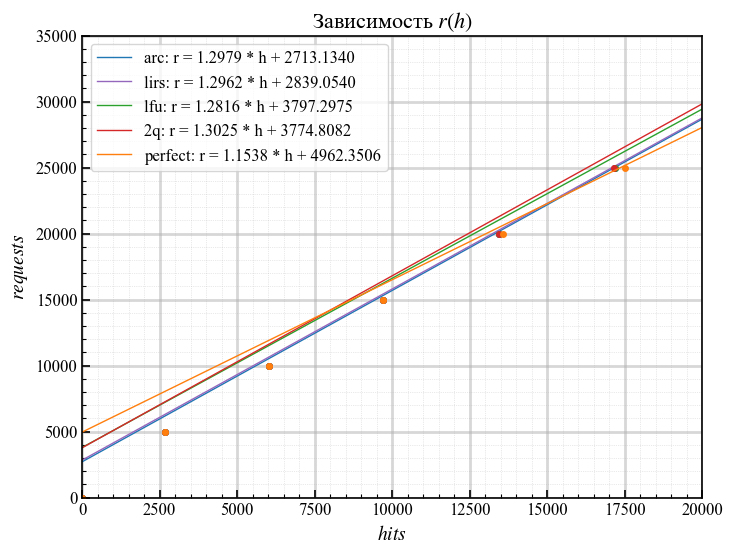

In [58]:
plt.figure()
plt.plot(dataarc5000['h'], dataarc5000['r'], 'o', color='tab:blue')

coeff, err, b = least_squares(dataarc5000['h'], dataarc5000['r'])
plt.plot(dataarc5000['h'], coeff * dataarc5000['h'] + b , color='tab:blue', label=f"arc: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalirs5000['h'], datalirs5000['r'], 'o', color='tab:purple')

coeff, err, b = least_squares(datalirs5000['h'], datalirs5000['r'])
plt.plot(datalirs5000['h'], coeff * datalirs5000['h'] + b , color='tab:purple', label=f"lirs: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(datalfu5000['h'], datalfu5000['r'], 'o', color='tab:green')

coeff, err, b = least_squares(datalfu5000['h'], datalfu5000['r'])
plt.plot(datalfu5000['h'], coeff * datalfu5000['h'] + b , color='tab:green', label=f"lfu: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(data2q5000['h'], data2q5000['r'], 'o', color='tab:red')

coeff, err, b = least_squares(data2q5000['h'], data2q['r'])
plt.plot(data2q5000['h'], coeff * data2q5000['h'] + b , color='tab:red', label=f"2q: r = {coeff:.4f} * h + {b:.4f}")

plt.plot(dataperf5000['h'], dataperf5000['r'], 'o', color='tab:orange')

coeff, err, b = least_squares(dataperf5000['h'], dataperf5000['r'])
plt.plot(dataperf5000['h'], coeff * dataperf5000['h'] + b , color='tab:orange', label=f"perfect: r = {coeff:.4f} * h + {b:.4f}")

plt.legend()


plt.xlim(0, 20000)
plt.ylim(0, 35000)
plt.minorticks_on()
plt.grid(which='major', lw = 2)
plt.grid(which='minor', color = '#aaa', ls=':')
plt.title("Зависимость $r(h)$")
plt.xlabel("$hits$")
plt.ylabel("$requests$")
plt.savefig('plot_5000_1lvl_start.png', dpi=500)
plt.show()
plt.close()
